# Orden de repago dentro del deudor

Cuando una persona con varias deudas deja de pagar, ¿a quién deja de pagarle primero? Este notebook explora la pregunta con la muestra de personas de CENDEU, de a poco y sin imponer una especificación de entrada. La idea de partida está en `Methodological_Notes/pecking_order.md`; lo que sigue es lo que los datos muestran cuando se la mira con cuidado.

La comparación relevante es dentro de la misma persona y el mismo mes. Si alguien pierde ingresos, eso afecta a todas sus deudas por igual, así que comparar sus relaciones entre sí absorbe la capacidad de pago y deja como fuente de variación al acreedor. Es el diseño de Khwaja y Mian, aplicado al repago en lugar del crédito.

**Resumen de lo que se encuentra**, desarrollado en las secciones:

1. La primera mora casi nunca es total: en torno al 97% de los primeros eventos afecta a algunas relaciones y no a otras, y la selectividad persiste seis meses después.
2. El orden por acreedor es marcado y estable. Lo que ordena no es banco contra fintech sino **quién está sentado sobre el flujo de ingresos del deudor**: MercadoLibre, bancos digitales, mutuales, y los bancos que pagan sueldos provinciales se cobran primero; retail, financieras de consumo y tarjetas no bancarias, último.
3. El agente pagador cobra primero *donde es agente pagador*: Macro en Salta, Jujuy, Misiones y Tucumán, y los bancos provinciales en su provincia, con más fuerza en provincias chicas.
4. La prioridad cambia con la fuente de ingreso del deudor en la dirección que predice el mecanismo: los jubilados protegen al banco público; los que tienen actividad registrada protegen a MercadoLibre y a los bancos digitales.
5. Una medida independiente, la recategorización obligatoria del corte de julio de 2026, reproduce el mismo orden.

Todo corre en la máquina local. Los intermedios con identificadores van a un directorio temporal fuera del repositorio y se borran al final. Las salidas son agregadas por acreedor o por categoría.

In [1]:
import os, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
from IPython.display import display, Markdown

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'Data/processed/ipc.dta').exists())
sys.path.insert(0, str(root / 'Code/analysis/pecking_order'))
import po
from po import (clogit, prep, add_borrower, cat_dummies, or_plot, save, ym_label, short_name,
                CATS, SIZE, AGE, HOME, MACRO, BLUE, OCHRE, OLIVE, INK, GREY, MIN_PERSONAS)
po.figure_style()
pd.set_option('display.width', 200)
pd.set_option('display.max_rows', 80)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

def es(x, dec=1):
    # número con convención local: punto de miles, coma decimal
    return f'{x:,.{dec}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')

tmp = po.workdir()
con = po.connect(tmp)
cat = po.categories()
con.register('cat_df', cat[['ent', 'cat']])
names = cat.set_index('ent').name
po.record_inputs(list(po.SAMPLE.glob('*.parquet')) + [po.CENDEU / 'padron.parquet', po.CENDEU / 'deudores.parquet',
                 root / 'Data/crosswalks/cendeu_lenders.csv'], '01')

## 1. La materia prima: primeros eventos de mora

**Definición.** Una persona es elegible en el mes *t* si en *t−1* tiene dos o más relaciones con saldo y todas están en situación 1. El evento es que una relación pase a situación 2 o peor en *t*. Se usa la entrada a situación 2 porque es la primera señal de impago, 31 a 90 días de atraso en cartera de consumo, y porque la recategorización obligatoria entre entidades recién se activa con diferencias de más de un nivel: desde un estado en que todas las relaciones están en 1, la primera caída no puede ser arrastre regulatorio (sección 9).

Cada relación tiene tres resultados posibles: sigue sana, cae, o sale (no aparece o queda en cero, lo que incluye cancelaciones). Julio de 2026 queda fuera como mes *t* porque el corte está incompleto.

In [2]:
EV = po.build_events(con, tmp)
# las tablas grandes quedan en parquet dentro del directorio temporal, no en memoria
con.execute(f'''COPY (SELECT e.*, coalesce(c.cat, 'Sin clasificar') AS cat, s.start_ym
  FROM read_parquet('{EV}') e LEFT JOIN cat_df c USING (ent)
  LEFT JOIN read_parquet('{(tmp / 'start.parquet').as_posix()}') s USING (ent, pid))
  TO '{(tmp / 'r.parquet').as_posix()}' (FORMAT parquet)''')
con.execute(f"CREATE VIEW r AS SELECT * FROM read_parquet('{(tmp / 'r.parquet').as_posix()}')")
monthly = con.execute('''
  WITH per AS (SELECT ym, pid, count(*) k, sum((outcome = 1)::INT) nb FROM r GROUP BY 1, 2)
  SELECT ym, count(*) AS elegibles, 100 * avg((nb > 0)::INT) AS tasa_evento,
         100 * sum((nb > 0 AND nb < k)::INT) / sum((nb > 0)::INT) AS pct_parcial,
         sum((nb > 0)::INT) AS eventos, sum((nb > 0 AND nb < k)::INT) AS parciales
  FROM per GROUP BY 1 ORDER BY 1''').fetchdf()
monthly['fecha'] = ym_label(monthly.ym)
by_k = con.execute('''
  WITH per AS (SELECT ym, pid, count(*) k, sum((outcome = 1)::INT) nb FROM r GROUP BY 1, 2)
  SELECT least(k, 5) AS relaciones, count(*) AS persona_mes, 100 * avg((nb > 0)::INT) AS tasa_evento,
         100 * sum((nb > 0 AND nb < k)::INT) / sum((nb > 0)::INT) AS pct_parcial
  FROM per GROUP BY 1 ORDER BY 1''').fetchdf()
by_k['relaciones'] = by_k.relaciones.astype(str).replace({'5': '5 o más'})
monthly.drop(columns='ym').to_csv(po.OUT / '01_eventos_mensuales.csv', index=False)
by_k.to_csv(po.OUT / '01_eventos_por_k.csv', index=False)
display(by_k)
display(Markdown(f'''Persona-mes elegibles en la muestra del 5%: **{es(by_k.persona_mes.sum(), 0)}**. Primeros eventos: **{es(monthly.eventos.sum(), 0)}**, de los cuales **{es(100 * monthly.parciales.sum() / monthly.eventos.sum())}%** son parciales. Tasa mensual de primer evento: mínimo {es(monthly.tasa_evento.min(), 2)}% ({monthly.loc[monthly.tasa_evento.idxmin(), 'fecha']:%m/%Y}), máximo {es(monthly.tasa_evento.max(), 2)}% ({monthly.loc[monthly.tasa_evento.idxmax(), 'fecha']:%m/%Y}).'''))

,relaciones,persona_mes,tasa_evento,pct_parcial
0,2,4245224,2.804,93.520
1,3,1717881,4.545,98.808
2,4,667083,6.592,99.591
3,5 o más,409744,10.127,99.872


Persona-mes elegibles en la muestra del 5%: **7.039.932**. Primeros eventos: **282.580**, de los cuales **96,9%** son parciales. Tasa mensual de primer evento: mínimo 2,83% (09/2024), máximo 5,36% (11/2025).

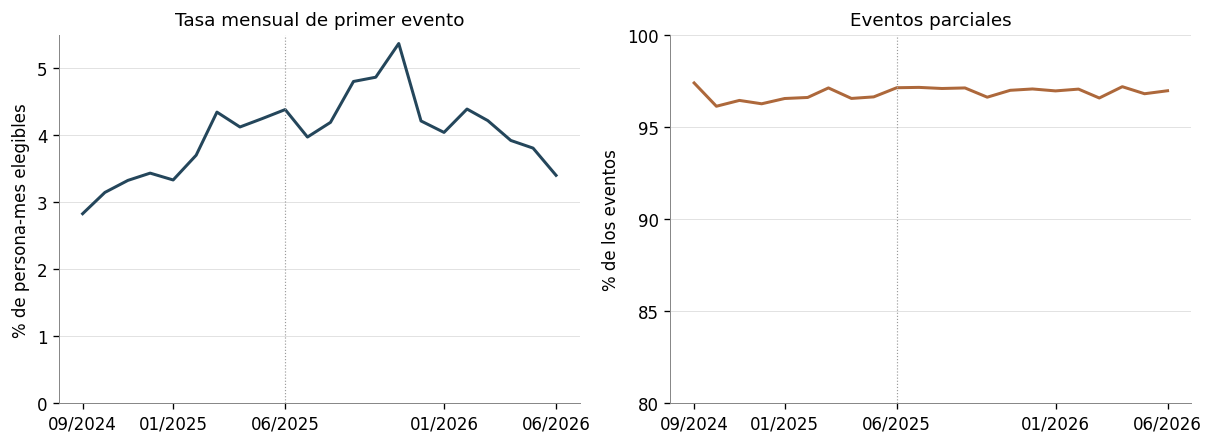

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout='constrained')
axes[0].plot(monthly.fecha, monthly.tasa_evento, color=BLUE)
axes[0].set(title='Tasa mensual de primer evento', ylabel='% de persona-mes elegibles', ylim=(0, None))
axes[1].plot(monthly.fecha, monthly.pct_parcial, color=OCHRE)
axes[1].set(title='Eventos parciales', ylabel='% de los eventos', ylim=(80, 100), yticks=[80, 85, 90, 95, 100])
for ax in axes:
    ax.grid(axis='y', color='#dddddd', linewidth=0.5)
    ax.axvline(pd.Timestamp('2025-06-01'), color=GREY, linewidth=0.7, linestyle=':')
    ax.set_xticks(pd.to_datetime(['2024-09-01', '2025-01-01', '2025-06-01', '2026-01-01', '2026-06-01']))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%Y'))
save(fig, '01_eventos'); plt.show()

La tasa de primer evento entre personas con historia limpia sube de algo menos de 3% mensual a fines de 2024 a un pico cerca de 5,4% en noviembre de 2025, y vuelve a 3,4% a mediados de 2026. Es la única serie de flujo limpia que tenemos del deterioro: a diferencia del stock de mora, no está contaminada por la deuda que queda sin darse de baja. El pico llega con dos o tres meses de rezago respecto de la volatilidad de tasas de julio a octubre de 2025, pero la suba había empezado antes; no hay discontinuidad en junio.

El hecho central de esta sección es el otro panel: **el primer impago casi nunca es total**. Incluso con dos relaciones, más del 90% de los eventos afecta a una sola. Queda por ver si es selección o simple desfasaje de fechas de vencimiento.

## 2. ¿Selección o calendario?

Si la persona simplemente dejó de pagar todo y los vencimientos caen en meses distintos, las relaciones que siguen sanas en *t* deberían caer en *t+1* o *t+2*. Si es selección, deberían seguir sanas por varios meses. Se siguen todas las relaciones de los eventos parciales en el panel.

In [4]:
con.execute('''CREATE TABLE disc_groups AS SELECT ym, pid FROM r GROUP BY 1, 2
               HAVING sum((outcome = 1)::INT) > 0 AND sum((outcome = 1)::INT) < count(*)''')
LONG = po.build_long(con, tmp, 'SELECT DISTINCT pid FROM disc_groups')
rows = []
for h in [1, 2, 3, 6, 9]:
    rows.append(con.execute(f'''
      SELECT e.outcome, {h} AS h, count(*) AS n,
        100 * avg((l.status = 1 AND l.amount_ars > 0)::INT) AS sana,
        100 * avg((l.status BETWEEN 2 AND 5)::INT) AS en_mora,
        100 * avg((l.pid IS NULL OR (l.amount_ars = 0 AND coalesce(l.status, 0) IN (0, 1)))::INT) AS fuera
      FROM r e JOIN disc_groups g USING (ym, pid)
      LEFT JOIN read_parquet('{LONG}') l ON l.pid = e.pid AND l.ent = e.ent AND l.ym = e.ym + {h}
      WHERE e.outcome IN (0, 1) AND e.ym + {h} < {po.YM_LAST}
      GROUP BY 1''').fetchdf())
pers = pd.concat(rows)
pers['relacion'] = pers.outcome.map({0: 'Sana en t', 1: 'Cae en t'})
pers.drop(columns='outcome').to_csv(po.OUT / '02_persistencia.csv', index=False)
display(pers.pivot(index='relacion', columns='h', values=['sana', 'en_mora', 'fuera']).round(1))

sana                             en_mora                             fuera                           
h              1      2      3      6      9       1      2      3      6      9     1     2      3      6      9
relacion                                                                                                         
Cae en t  21.000 25.400 24.000 20.400 17.800  73.700 66.300 64.900 62.500 59.700 5.300 8.300 11.100 17.100 22.500
Sana en t 85.600 78.000 71.400 55.600 46.200  10.600 15.800 20.300 30.800 35.800 3.800 6.200  8.300 13.700 18.000

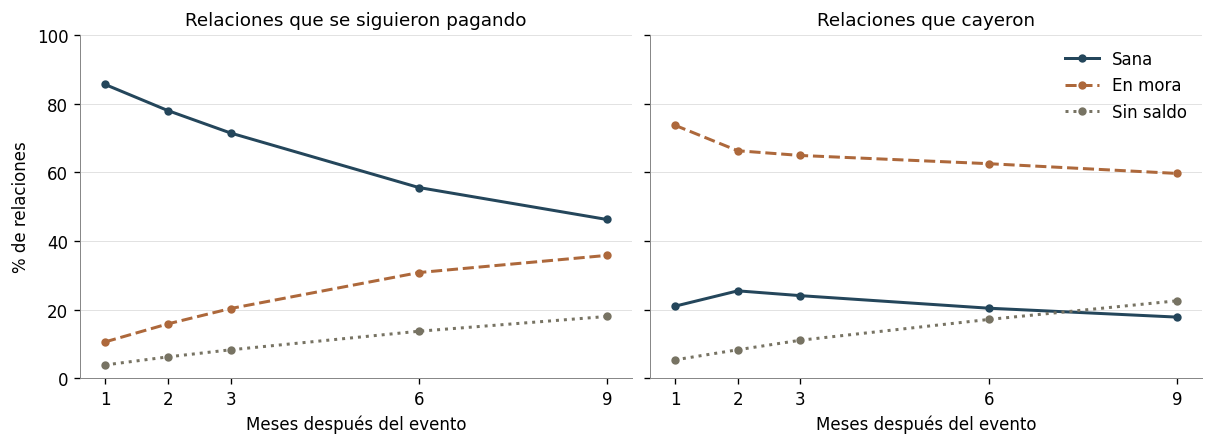

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True, layout='constrained')
for ax, lab in zip(axes, ['Sana en t', 'Cae en t']):
    g = pers[pers.relacion.eq(lab)].sort_values('h')
    ax.plot(g.h, g.sana, color=BLUE, marker='o', markersize=4, label='Sana')
    ax.plot(g.h, g.en_mora, color=OCHRE, marker='o', markersize=4, linestyle='--', label='En mora')
    ax.plot(g.h, g.fuera, color=OLIVE, marker='o', markersize=4, linestyle=':', label='Sin saldo')
    ax.set(title={'Sana en t': 'Relaciones que se siguieron pagando', 'Cae en t': 'Relaciones que cayeron'}[lab],
           xlabel='Meses después del evento', xticks=[1, 2, 3, 6, 9], ylim=(0, 100))
    ax.grid(axis='y', color='#dddddd', linewidth=0.5)
axes[0].set_ylabel('% de relaciones')
axes[1].legend()
save(fig, '02_persistencia'); plt.show()

La selección persiste. De las relaciones que la persona siguió pagando en el mes del evento, algo más de la mitad sigue sana seis meses después y menos de un tercio entró en mora; de las que cayeron, cerca de dos tercios siguen en mora y solo una de cada cinco se normaliza. El calendario de vencimientos explica una parte del arrastre del primer mes, no el patrón. Parte de lo que cae después es además recategorización obligatoria, que empuja la mora de un acreedor a los demás (sección 9), así que estas cifras subestiman la persistencia de la selección.

## 3. ¿A quién se le deja de pagar primero?

Primero, una medida sin modelo. En cada evento parcial con *k* relaciones y *m* caídas, si la persona eligiera al azar, cada relación caería con probabilidad *m/k*. Sumando por categoría de acreedor se obtiene un número esperado de caídas; el cociente observado sobre esperado dice si la categoría cae más (mayor a 1) o menos (menor a 1) que el azar, dentro de la misma persona y el mismo mes.

Las categorías vienen de `po.categories()`: rango de código BCRA y grupo del crosswalk, con dos correcciones al crosswalk (los códigos 44xxx, 45xxx y 65xxx son compañías financieras, no fideicomisos) y MercadoLibre separado del resto de las fintech, porque es tres cuartos del grupo. Se excluyen garantías, fideicomisos financieros y el código 150, absorbido por Galicia en junio de 2025.

In [6]:
con.execute('''CREATE VIEW r2 AS SELECT * FROM r
  WHERE cat NOT IN ('Garantía', 'Sin clasificar', 'Fideicomiso financiero') AND ent <> 150''')
con.execute(f'''COPY (SELECT ym, pid, count(*) k2, sum((outcome = 1)::INT) nb, sum(amt_prev) tot
               FROM r2 GROUP BY 1, 2 HAVING count(*) >= 2) TO '{(tmp / 'g2.parquet').as_posix()}' (FORMAT parquet)''')
con.execute(f"CREATE VIEW g2 AS SELECT * FROM read_parquet('{(tmp / 'g2.parquet').as_posix()}')")
oe = con.execute('''
  SELECT r2.cat, count(*) AS relaciones, 100 * avg((outcome = 1)::INT) AS tasa_caida,
    sum((outcome = 1)::INT) FILTER (WHERE nb > 0 AND nb < k2) AS observadas,
    sum(nb::DOUBLE / k2) FILTER (WHERE nb > 0 AND nb < k2) AS esperadas
  FROM r2 JOIN g2 USING (ym, pid) GROUP BY 1''').fetchdf()
oe['obs_sobre_esp'] = oe.observadas / oe.esperadas
oe = oe.sort_values('obs_sobre_esp').reset_index(drop=True)
oe.to_csv(po.OUT / '03_observado_esperado.csv', index=False)
display(oe)

,cat,relaciones,tasa_caida,observadas,esperadas,obs_sobre_esp
0,MercadoLibre,2721425,0.900,"21,583.000","49,935.334",0.432
1,Mutual o cooperativa,176490,1.621,"2,748.000","3,404.708",0.807
2,Banco digital,202493,1.903,"3,486.000","4,041.032",0.863
3,Compañía financiera,159691,1.225,"1,889.000","1,986.952",0.951
4,Otro PNFC,428050,3.414,"13,574.000","13,114.795",1.035
5,Banco privado,6531268,1.447,"90,423.000","86,408.044",1.046
6,Otras fintech,222767,3.875,"8,232.000","7,842.124",1.050
7,Banco público,2902462,1.482,"41,423.000","39,100.805",1.059
8,Financiera digital,976965,2.387,"20,912.000","19,282.683",1.084
9,Tarjeta no bancaria,2842827,2.117,"55,922.000","46,449.449",1.204


El orden aparece sin necesidad de modelo. MercadoLibre cae menos de la mitad de lo que caería al azar; retail y financieras de consumo, un tercio más. Los bancos quedan cerca de 1. La tasa de caída incondicional (segunda columna) muestra por qué hay que comparar dentro de la persona: MercadoLibre tiene una tasa baja, pero también la tienen los bancos, y esas tasas mezclan quién es el deudor con quién es el acreedor.

Ahora el modelo. Logit condicional con efecto fijo de persona-mes sobre los eventos con exactamente una relación caída: dado que una de las *k* relaciones cae, ¿cuál? Las razones de chances son relativas a la banca privada. Se agregan dos controles que viven a nivel relación: tamaño relativo dentro de la deuda de la persona, y antigüedad observada de la relación, porque los préstamos nuevos tienen más mora temprana.

In [7]:
d = con.execute('''SELECT r2.ym, r2.pid, r2.ent, r2.cat, r2.amt_prev, r2.outcome, r2.status_t, r2.start_ym,
                          g2.k2, g2.nb, r2.amt_prev::DOUBLE / g2.tot AS share
                   FROM r2 JOIN g2 USING (ym, pid) WHERE g2.nb > 0 AND g2.nb < g2.k2''').fetchdf()
d = prep(d)
C = cat_dummies(d)
models = {}
for name, X in [('Solo acreedor', C), ('+ tamaño relativo', C + SIZE), ('+ antigüedad', C + SIZE + AGE)]:
    models[name], info = clogit(d, 'y', X)
print(info)
tab = pd.concat({k: v['or'] for k, v in models.items()}, axis=1).loc[C]
tab.index = [c[2:] for c in tab.index]
display(tab)
display(models['+ antigüedad'].loc[SIZE + AGE, ['or', 'lo', 'hi']])
pd.concat(models, names=['modelo']).to_csv(po.OUT / '03_logit_condicional_categorias.csv')

{'grupos': 247939, 'relaciones': 757012, 'personas': 197332, 'iteraciones': 6}


,Solo acreedor,+ tamaño relativo,+ antigüedad
Banco público,1.043,1.048,1.051
Banco digital,0.575,0.569,0.541
Compañía financiera,0.901,0.897,0.871
Financiera digital,0.964,0.954,0.929
Tarjeta no bancaria,1.186,1.177,1.183
MercadoLibre,0.333,0.327,0.326
Otras fintech,1.067,1.060,1.004
Retail,1.776,1.762,1.732
Financiera de consumo,1.741,1.720,1.665
Mutual o cooperativa,0.769,0.759,0.745


,or,lo,hi
sh_lt10,0.897,0.881,0.912
sh_10_25,0.944,0.928,0.960
sh_50p,0.890,0.877,0.902
age_lt3,1.080,1.061,1.098
age_3_6,1.242,1.219,1.266
age_6_12,1.152,1.132,1.173


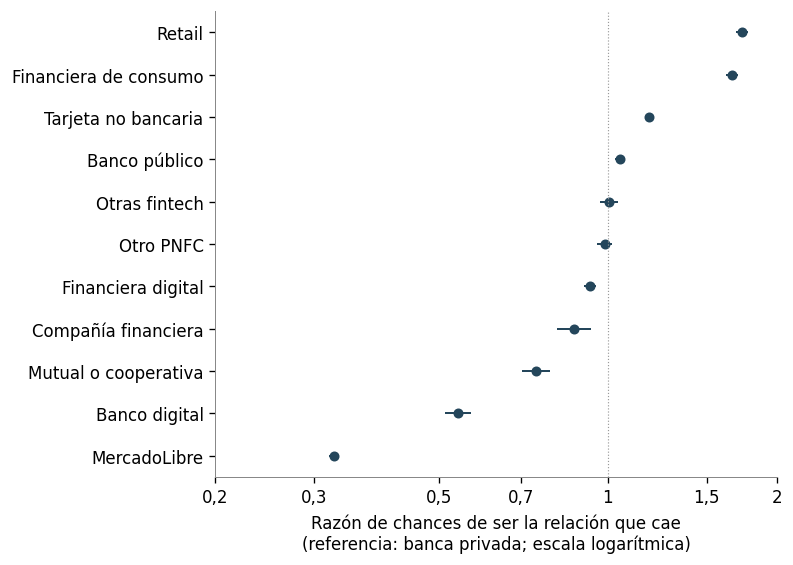

In [8]:
m3 = models['+ antigüedad'].loc[C].copy()
m3.index = [c[2:] for c in m3.index]
m3 = m3.sort_values('or', ascending=False)
fig, ax = plt.subplots(figsize=(6.5, 4.6), layout='constrained')
or_plot(ax, m3)
ax.set_xlabel('Razón de chances de ser la relación que cae\n(referencia: banca privada; escala logarítmica)')
save(fig, '03_orden_categorias'); plt.show()

El orden sobrevive a los controles casi sin moverse. MercadoLibre tiene un tercio de las chances de ser la relación que cae que un banco privado; bancos digitales, algo más de la mitad; mutuales y cooperativas, tres cuartos. Retail y financieras de consumo tienen cerca de 70% más chances. La relación con el tamaño relativo no es monótona: se protegen tanto las deudas chicas como la más grande, y caen más las intermedias. Las relaciones de tres a doce meses caen más que las viejas, que es la mora temprana habitual en carteras nuevas.

La lectura "fintech contra bancos" no describe esto. Las otras fintech, las que prestan online sin billetera, quedan en el mismo lugar que la banca privada; MercadoLibre tiene un tercio de sus chances. Lo que separa a MercadoLibre de ellas no es la tecnología de originación sino que MercadoLibre tiene la cuenta donde entra la plata. Una advertencia sobre la referencia: la banca privada agrupada incluye bancos que pagan sueldos provinciales, que resultan muy protegidos (sección 5). Contra una referencia sin ellos, sección 6, todas las razones de chances bajan algo, y el orden se mantiene.

El estimador está escrito a mano para poder trabajar por bloques y agrupar errores por persona. La celda siguiente lo contrasta con `ConditionalLogit` de statsmodels sobre una submuestra de 25.000 eventos, si statsmodels está instalado.

In [9]:
try:
    from statsmodels.discrete.conditional_models import ConditionalLogit
    s = d[d.groupby('grp').y.transform('sum').eq(1)]
    s = s[s.grp.isin(s.grp.drop_duplicates().sample(25000, random_state=1))].sort_values('grp')
    Xv = C + SIZE + AGE
    ref = ConditionalLogit(s.y.values, s[Xv].astype(float).values, groups=s.grp.values).fit(disp=0, maxiter=200)
    own = clogit(s, 'y', Xv)[0]
    print('Máxima diferencia absoluta en coeficientes:', f'{np.abs(own.coef.values - ref.params).max():.4f}')
except ImportError:
    print('statsmodels no está instalado; se omite el contraste.')

Máxima diferencia absoluta en coeficientes: 0.0038


## 4. Amenazas

Cinco lecturas alternativas que podrían producir el mismo orden sin que haya prioridad de repago.

**(a) Salidas.** MercadoLibre presta a plazos cortos y sus relaciones terminan seguido. Una relación que se cancela no puede caer. Se reestima excluyendo del conjunto de elección las relaciones que salen en *t*, y restringiendo a eventos sin ninguna salida.

**(b) Composición de la cartera.** Personas con dos relaciones contra personas con más.

**(c) Criterio de reporte.** Si una categoría reportara el atraso más tarde, pasando de 1 a 3 sin pasar por 2, parecería protegida. Se mira a qué situación entra cada categoría en el evento.

**(d) Rezago.** Si la protección fuera solo demora en reportar, las relaciones protegidas deberían alcanzar a las demás en *t+3* o *t+6*.

**(e) Tamaño.** MercadoLibre suele ser una deuda chica dentro del total de la persona.

In [10]:
X = C + SIZE + AGE
nx = d.groupby('grp').outcome.transform(lambda s: (s == 2).sum())
rob = {'Base': models['+ antigüedad']['or'],
       'Sin relaciones que salen': clogit(d[d.outcome != 2], 'y', X)[0]['or'],
       'Eventos sin salidas': clogit(d[nx == 0], 'y', X)[0]['or'],
       'Solo dos relaciones': clogit(d[d.k2 == 2], 'y', X)[0]['or'],
       'Tres o más': clogit(d[d.k2 >= 3], 'y', X)[0]['or']}
rob = pd.concat(rob, axis=1).loc[C]
rob.index = [c[2:] for c in rob.index]
rob.to_csv(po.OUT / '04_robustez.csv')
display(rob)

,Base,Sin relaciones que salen,Eventos sin salidas,Solo dos relaciones,Tres o más
Banco público,1.051,1.054,1.049,1.033,1.065
Banco digital,0.541,0.544,0.561,0.690,0.492
Compañía financiera,0.871,0.883,0.863,1.018,0.810
Financiera digital,0.929,0.973,0.980,1.458,0.794
Tarjeta no bancaria,1.183,1.156,1.171,1.573,1.028
MercadoLibre,0.326,0.327,0.329,0.351,0.285
Otras fintech,1.004,1.008,1.023,1.716,0.838
Retail,1.732,1.712,1.720,2.144,1.567
Financiera de consumo,1.665,1.658,1.661,2.251,1.444
Mutual o cooperativa,0.745,0.777,0.767,1.031,0.654


In [11]:
entry = con.execute('''SELECT cat, count(*) AS eventos,
    100 * avg((status_t = 2)::INT) AS a_situacion_2, 100 * avg((status_t >= 3)::INT) AS a_3_o_peor
  FROM r2 WHERE outcome = 1 GROUP BY 1 ORDER BY eventos DESC''').fetchdf()
con.register('dsel', d[['ym', 'pid', 'ent', 'cat', 'outcome']])
lag = con.execute(f'''SELECT e.cat,
    100 * avg((l.status BETWEEN 2 AND 5)::INT) FILTER (WHERE l.ym = e.ym + 3) AS mora_en_t3,
    100 * avg((l.status BETWEEN 2 AND 5)::INT) FILTER (WHERE l.ym = e.ym + 6) AS mora_en_t6
  FROM dsel e JOIN read_parquet('{LONG}') l ON l.pid = e.pid AND l.ent = e.ent AND l.ym IN (e.ym + 3, e.ym + 6)
  WHERE e.outcome = 0 GROUP BY 1''').fetchdf()
chk = entry.merge(lag, on='cat', how='left').sort_values('mora_en_t6').reset_index(drop=True)
chk.to_csv(po.OUT / '04_reporte_y_rezago.csv', index=False)
display(chk)

,cat,eventos,a_situacion_2,a_3_o_peor,mora_en_t3,mora_en_t6
0,Mutual o cooperativa,2864,95.915,4.085,11.691,18.072
1,MercadoLibre,24551,99.898,0.102,13.000,23.717
2,Banco público,43056,99.008,0.992,15.281,24.920
3,Banco privado,94625,98.975,1.025,17.531,28.316
4,Compañía financiera,1968,99.797,0.203,20.971,32.222
5,Financiera digital,23332,99.533,0.467,27.953,33.726
6,Otro PNFC,14619,96.422,3.578,28.053,34.838
7,Tarjeta no bancaria,60239,99.894,0.106,24.372,37.235
8,Retail,24300,99.617,0.383,28.430,39.157
9,Financiera de consumo,21868,99.858,0.142,34.519,45.495


In [12]:
d['meli_chica'] = d['c_MercadoLibre'] * (d.share < 0.10)
d['meli_mayor'] = d['c_MercadoLibre'] * (d.share >= 0.50)
b, _ = clogit(d, 'y', X + ['meli_chica', 'meli_mayor'])
base = b.loc['c_MercadoLibre', 'coef']
display(pd.Series({'MercadoLibre, 10 a 50% de la deuda': np.exp(base),
                   'MercadoLibre, menos de 10%': np.exp(base + b.loc['meli_chica', 'coef']),
                   'MercadoLibre, 50% o más': np.exp(base + b.loc['meli_mayor', 'coef'])}, name='razón de chances').to_frame())
d.drop(columns=['meli_chica', 'meli_mayor'], inplace=True)

,razón de chances
"MercadoLibre, 10 a 50% de la deuda",0.346
"MercadoLibre, menos de 10%",0.271
"MercadoLibre, 50% o más",0.596


Ninguna de las cinco se sostiene.

Excluir salidas no mueve el orden. En los eventos con solo dos relaciones el orden se mantiene en los extremos, MercadoLibre y bancos digitales arriba, retail y financieras de consumo abajo, aunque las mutuales pierden su ventaja: su protección aparece en carteras de tres o más relaciones. Todas las categorías entran al evento por situación 2 en más del 95% de los casos, así que no hay una categoría que reporte con un escalón de demora. Y las relaciones protegidas no alcanzan a las demás: seis meses después, las de MercadoLibre y las mutuales que se siguieron pagando tienen menos mora que las de la banca privada, no más.

La excepción son los bancos digitales. Se los protege en el mes del evento, pero sus relaciones protegidas caen después a una tasa alta, cerca de 46% a seis meses, la más alta de la tabla junto con las otras fintech. En ellos la ventaja se parece más a una demora que a una prioridad: el débito funciona mientras el ingreso sigue entrando a esa cuenta, y deja de funcionar cuando la persona lo desvía.

El tamaño matiza pero no explica. MercadoLibre se protege más cuando es una deuda chica, lo esperable si el débito sobre el saldo de la billetera cubre mejor cuotas chicas, pero sigue protegido cuando es la deuda más grande de la persona.

## 5. Por entidad

Las categorías agrupan entidades muy distintas. Se estima el mismo modelo con una dummy por entidad para las que tienen al menos 2.000 relaciones en eventos parciales; el resto entra por categoría. La referencia es Galicia junto con los bancos privados chicos.

In [13]:
cnt = d.ent.value_counts()
big = [e for e in cnt.index if cnt[e] >= 2000 and e != 7]
XE = []
for e in big:
    d[f'e_{e}'] = d.ent.eq(e).astype('float32'); XE.append(f'e_{e}')
for k in CATS:
    col = f'r_{k}'
    d[col] = (d.cat.eq(k) & ~d.ent.isin(big)).astype('float32')
    if d[col].sum() > 0: XE.append(col)
be, info = clogit(d, 'y', XE + SIZE + AGE)
print(info)
ent_tab = be.loc[[x for x in XE if x.startswith('e_')]].copy()
ent_tab['ent'] = [int(x[2:]) for x in ent_tab.index]
ent_tab['entidad'] = [short_name(e, names.get(e, e)) for e in ent_tab.ent]
ent_tab['categoria'] = ent_tab.ent.map(cat.set_index('ent').cat)
ent_tab['relaciones'] = ent_tab.ent.map(cnt)
ent_tab = ent_tab.sort_values('or').reset_index(drop=True)
ent_tab[['ent', 'entidad', 'categoria', 'relaciones', 'or', 'lo', 'hi']].to_csv(po.OUT / '05_logit_condicional_entidades.csv', index=False)
display(ent_tab[['entidad', 'categoria', 'relaciones', 'or', 'lo', 'hi']])
d.drop(columns=[c for c in d.columns if c.startswith(('e_', 'r_'))], inplace=True)

{'grupos': 247939, 'relaciones': 757012, 'personas': 197332, 'iteraciones': 6}


,entidad,categoria,relaciones,or,lo,hi
0,Santiago del Estero,Banco privado,5020,0.208,0.188,0.229
1,MercadoLibre,MercadoLibre,136869,0.244,0.237,0.251
2,Industrial,Banco privado,4538,0.253,0.229,0.279
3,Chaco,Banco público,4764,0.321,0.294,0.351
4,Alau Tecnologia,Otro PNFC,2098,0.337,0.291,0.389
5,Brubank,Banco digital,2089,0.344,0.299,0.395
6,Macro,Banco privado,33920,0.369,0.355,0.383
7,Corrientes,Banco público,2534,0.384,0.341,0.432
8,Ualá,Banco digital,10694,0.420,0.395,0.446
9,Del Sol,Banco privado,3516,0.444,0.400,0.493


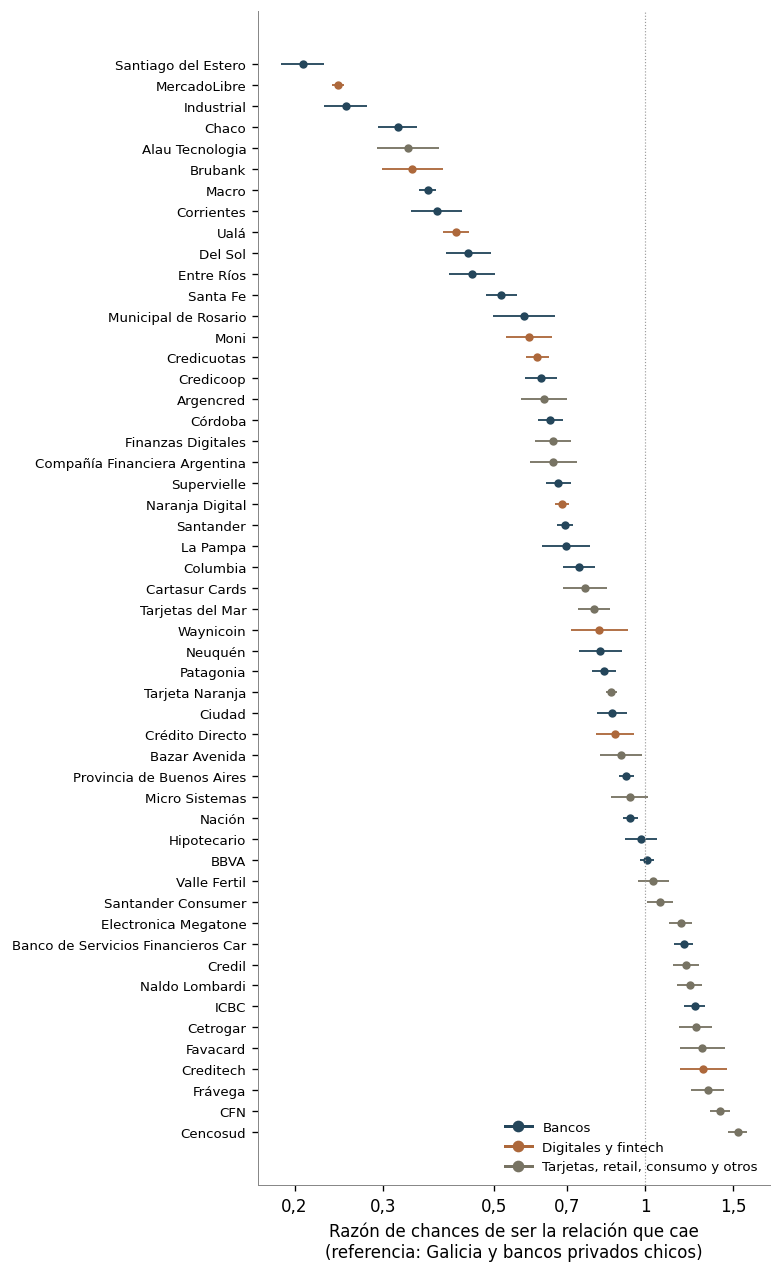

In [14]:
family = {'Banco privado': BLUE, 'Banco público': BLUE, 'Banco digital': OCHRE, 'MercadoLibre': OCHRE,
          'Financiera digital': OCHRE, 'Otras fintech': OCHRE}
fig, ax = plt.subplots(figsize=(6.4, 10.5), layout='constrained')
t = ent_tab.iloc[::-1].reset_index(drop=True)
for i, row in t.iterrows():
    col = family.get(row.categoria, OLIVE)
    ax.hlines(i, row.lo, row.hi, color=col, linewidth=1.1)
    ax.plot(row['or'], i, 'o', color=col, markersize=4)
ax.set_yticks(range(len(t)))
ax.set_yticklabels(t.entidad, fontsize=8)
ax.axvline(1, color=GREY, linewidth=0.7, linestyle=':')
ax.set_xscale('log')
ticks = [0.2, 0.3, 0.5, 0.7, 1, 1.5]
ax.set_xticks(ticks); ax.set_xticklabels([f'{x:g}'.replace('.', ',') for x in ticks]); ax.minorticks_off()
ax.set_xlabel('Razón de chances de ser la relación que cae\n(referencia: Galicia y bancos privados chicos)')
ax.legend(handles=[Line2D([], [], color=BLUE, marker='o', label='Bancos'),
                   Line2D([], [], color=OCHRE, marker='o', label='Digitales y fintech'),
                   Line2D([], [], color=OLIVE, marker='o', label='Tarjetas, retail, consumo y otros')],
          loc='lower right', fontsize=8)
save(fig, '05_orden_entidades'); plt.show()

Por entidad aparece algo que las categorías tapaban. Entre los bancos, los más protegidos no son los grandes privados sino **los que pagan sueldos públicos provinciales**: Santiago del Estero, Chaco, Corrientes, Entre Ríos, Santa Fe, Córdoba, y Macro, que es agente financiero de cuatro provincias. Del otro lado, los bancos grandes sin ese rol (Galicia, BBVA, ICBC) y el banco de Carrefour están entre los que caen primero. Brubank y Ualá están arriba, con MercadoLibre. Naranja Digital, que opera la billetera Naranja X, está bastante mejor que Tarjeta Naranja. Las cadenas comerciales, Cencosud, Frávega, Cetrogar, Naldo y Megatone, y las financieras de consumo cierran la tabla.

Esto sugiere un mecanismo concreto: se paga primero a quien controla la cuenta donde entra el ingreso, porque puede debitar la cuota antes de que la persona decida. Las próximas dos secciones lo ponen a prueba con la geografía y con la fuente de ingreso del deudor, que el padrón permite observar.

## 6. El agente pagador cobra primero donde es agente pagador

Si la protección de un banco provincial viene de pagar los sueldos públicos, debería concentrarse en deudores que viven en esa provincia. Si viene de la marca, del tipo de producto o de la clientela, no debería importar dónde vive el deudor. La provincia sale del padrón (corte de julio de 2026, domicilio actual). Para Macro, la provincia relevante es cualquiera de las cuatro donde es agente financiero.

Se reestima el modelo por categorías con los bancos provinciales y Macro fuera de sus categorías, separados en *en casa* y *fuera*. La referencia pasa a ser la banca privada sin rol de agente pagador. Por el compromiso de la Ley 25.326, cualquier celda geográfica con menos de 500 personas se suprime.

In [15]:
pad = con.execute(f'''SELECT hash(cuit) AS pid, province, activity, birth_date
  FROM read_parquet('{(po.CENDEU / 'padron.parquet').as_posix()}')
  WHERE hash(cuit) IN (SELECT DISTINCT pid FROM disc_groups)''').fetchdf().drop_duplicates('pid')
d = add_borrower(d, pad)
print(f'Relaciones con persona encontrada en el padrón: {d.province.notna().mean():.2%}')
CB = cat_dummies(d, split_banks=True)
bb, info = clogit(d, 'y', CB + SIZE + AGE)
print(info)
bb_show = bb.loc[CB, ['or', 'lo', 'hi']].copy()
bb_show.index = [i[2:] if i.startswith('c_') else {'pb_home': 'Banco provincial, en casa', 'pb_away': 'Banco provincial, fuera',
                 'macro_home': 'Macro, en sus provincias', 'macro_away': 'Macro, fuera'}[i] for i in bb_show.index]
bb.to_csv(po.OUT / '06_logit_bancos_separados.csv')
display(bb_show.sort_values('or'))

Relaciones con persona encontrada en el padrón: 99.99%


{'grupos': 247939, 'relaciones': 757012, 'personas': 197332, 'iteraciones': 6}


,or,lo,hi
"Macro, en sus provincias",0.218,0.205,0.231
MercadoLibre,0.276,0.270,0.282
Banco digital,0.461,0.437,0.487
Mutual o cooperativa,0.608,0.573,0.644
"Macro, fuera",0.628,0.602,0.654
"Banco provincial, en casa",0.691,0.675,0.707
Compañía financiera,0.730,0.680,0.784
Financiera digital,0.776,0.756,0.796
"Banco provincial, fuera",0.783,0.744,0.824
Otro PNFC,0.817,0.793,0.843


In [16]:
prov = [e for e in HOME if d.ent.eq(e).sum() >= 1500]
XP = [c for c in CB if c not in ('pb_home', 'pb_away')]
for e in prov:
    d[f'h_{e}'] = (d.ent.eq(e) & d.province.eq(HOME[e])).astype('float32')
    d[f'a_{e}'] = (d.ent.eq(e) & d.province.ne(HOME[e])).astype('float32')
    XP += [f'h_{e}', f'a_{e}']
d['pb_resto'] = d.ent.isin([e for e in HOME if e not in prov]).astype('float32')
bp, info = clogit(d, 'y', XP + ['pb_resto'] + SIZE + AGE)
rows = []
for e in prov + [MACRO]:
    hk, ak = ('macro_home', 'macro_away') if e == MACRO else (f'h_{e}', f'a_{e}')
    ph, pa = d.loc[d[hk].eq(1), 'pid'].nunique(), d.loc[d[ak].eq(1), 'pid'].nunique()
    ok = pa >= MIN_PERSONAS
    rows.append({'banco': short_name(e, names[e]),
                 'or_en_casa': bp.loc[hk, 'or'], 'lo_casa': bp.loc[hk, 'lo'], 'hi_casa': bp.loc[hk, 'hi'], 'personas_casa': ph,
                 'or_fuera': bp.loc[ak, 'or'] if ok else np.nan, 'lo_fuera': bp.loc[ak, 'lo'] if ok else np.nan,
                 'hi_fuera': bp.loc[ak, 'hi'] if ok else np.nan, 'personas_fuera': pa if ok else np.nan})
provt = pd.DataFrame(rows).sort_values('or_en_casa').reset_index(drop=True)
provt['personas_fuera'] = provt.personas_fuera.astype('Int64')
assert (provt.personas_casa >= MIN_PERSONAS).all()
provt.to_csv(po.OUT / '06_agente_pagador.csv', index=False)
display(provt)
d.drop(columns=[c for c in d.columns if c.startswith(('h_', 'a_'))] + ['pb_resto'], inplace=True)

,banco,or_en_casa,lo_casa,hi_casa,personas_casa,or_fuera,lo_fuera,hi_fuera,personas_fuera
0,Santiago del Estero,0.194,0.170,0.220,2379,0.293,0.253,0.340,1500
1,Macro,0.212,0.200,0.224,11839,0.624,0.598,0.650,14923
2,Formosa,0.302,0.259,0.351,1484,NaN,NaN,NaN,<NA>
3,Chaco,0.357,0.327,0.390,3552,NaN,NaN,NaN,<NA>
4,La Rioja,0.362,0.305,0.431,1164,NaN,NaN,NaN,<NA>
5,San Juan,0.363,0.314,0.420,1270,NaN,NaN,NaN,<NA>
6,Corrientes,0.404,0.357,0.456,1797,NaN,NaN,NaN,<NA>
7,Entre Ríos,0.475,0.423,0.533,2171,NaN,NaN,NaN,<NA>
8,Chubut,0.512,0.445,0.590,1304,NaN,NaN,NaN,<NA>
9,Santa Fe,0.582,0.542,0.624,4761,NaN,NaN,NaN,<NA>


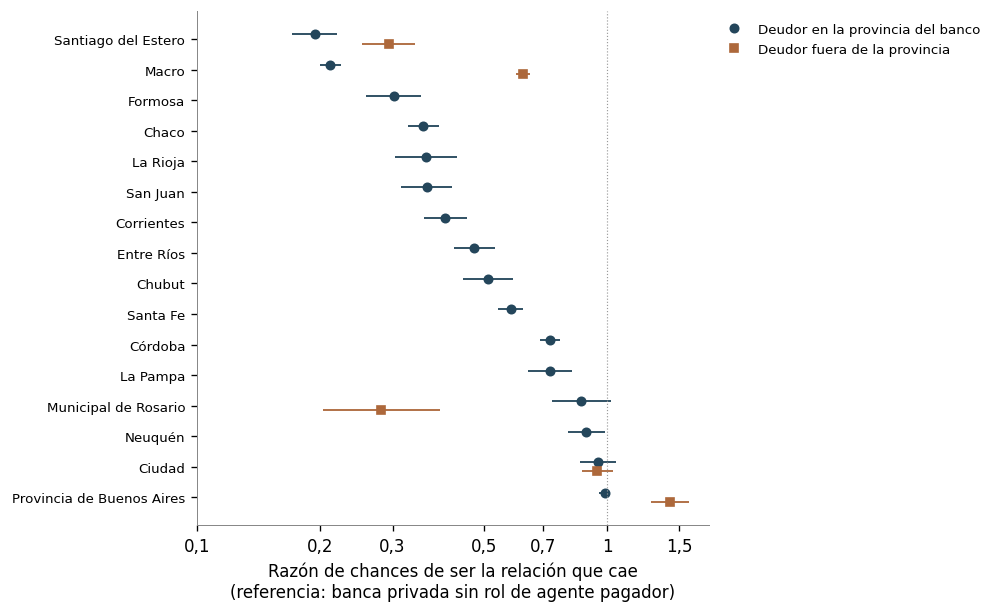

In [17]:
fig, ax = plt.subplots(figsize=(8.2, 5.0), layout='constrained')
t = provt.iloc[::-1].reset_index(drop=True)
y = np.arange(len(t))
ax.hlines(y + 0.15, t.lo_casa, t.hi_casa, color=BLUE, linewidth=1.1)
ax.plot(t.or_en_casa, y + 0.15, 'o', color=BLUE, markersize=5, label='Deudor en la provincia del banco')
ok = t.or_fuera.notna()
ax.hlines(y[ok] - 0.15, t.lo_fuera[ok], t.hi_fuera[ok], color=OCHRE, linewidth=1.1)
ax.plot(t.or_fuera[ok], y[ok] - 0.15, 's', color=OCHRE, markersize=4.5, label='Deudor fuera de la provincia')
ax.set_yticks(y); ax.set_yticklabels(t.banco, fontsize=8)
ax.axvline(1, color=GREY, linewidth=0.7, linestyle=':'); ax.set_xscale('log')
ticks = [0.1, 0.2, 0.3, 0.5, 0.7, 1, 1.5]
ax.set_xticks(ticks); ax.set_xticklabels([f'{x:g}'.replace('.', ',') for x in ticks]); ax.minorticks_off()
ax.set_xlabel('Razón de chances de ser la relación que cae\n(referencia: banca privada sin rol de agente pagador)')
ax.legend(loc='upper left', bbox_to_anchor=(1.0, 1.0), fontsize=8)
save(fig, '06_agente_pagador'); plt.show()

El resultado más limpio es Macro: dentro de sus cuatro provincias tiene chances cercanas a un quinto de las de la banca privada de referencia; fuera de ellas, alrededor de dos tercios. Es el mismo banco, con los mismos productos, y la diferencia está exactamente donde paga sueldos públicos. Entre los bancos provinciales, solo cinco tienen soporte suficiente para comparar fuera de casa. Santiago del Estero y Provincia de Buenos Aires van en la misma dirección que Macro; Ciudad no muestra diferencia; el Municipal de Rosario va en sentido contrario, con pocas personas fuera y un intervalo amplio, y con un banco municipal la provincia no es además la unidad correcta. La evidencia de *en casa contra fuera* descansa entonces sobre todo en Macro. Lo que sí es sistemático es el orden *en casa*: la protección es más fuerte cuanto más chica es la provincia. Santiago del Estero, Formosa, Chaco, La Rioja y San Juan arriba; Córdoba y La Pampa en el medio; Neuquén, Ciudad y Provincia de Buenos Aires cerca de 1. Es el gradiente que se esperaría si lo que importa es qué fracción de la clientela cobra su sueldo en ese banco, porque el peso del empleo público provincial es mucho mayor en las provincias chicas.

Una advertencia que hay que mantener: en provincias chicas el banco provincial es también el que tiene más sucursales y, a veces, la única alternativa. Una persona podría pagarle primero para no perder acceso, no porque le debite el sueldo. Las dos lecturas predicen *en casa* mejor que *fuera*. La sección siguiente ayuda a separarlas.

## 7. La prioridad sigue a la fuente de ingreso

Si el mecanismo es el débito sobre el flujo, la protección de cada acreedor debería depender de por dónde cobra el deudor. El padrón da dos cortes útiles. Quien no tiene actividad registrada es, en su mayoría, asalariado o jubilado; quien la tiene es monotributista o autónomo, y cobra por transferencias, QR o ventas. La edad separa a los jubilados, cuyo haber llega a un banco pagador de ANSES.

Predicciones: los jubilados deberían proteger a la banca pública y no a MercadoLibre; los que tienen actividad registrada, al revés; y la protección del banco provincial en casa debería ser más fuerte entre quienes no tienen actividad registrada.

In [18]:
groups = {'Sin actividad, menor de 65': ~d.con_actividad & (d.edad < 65),
          'Comercio, menor de 65': d.comercio & (d.edad < 65),
          'Otra actividad, menor de 65': d.con_actividad & ~d.comercio & (d.edad < 65),
          '65 años o más': d.edad >= 65}
het, info_h = {}, {}
for lab, m in groups.items():
    het[lab], info_h[lab] = clogit(d[m], 'y', CB + SIZE + AGE)
display(pd.DataFrame(info_h).T)
keys = ['c_MercadoLibre', 'c_Banco digital', 'c_Banco público', 'pb_home', 'macro_home', 'c_Mutual o cooperativa', 'c_Otras fintech', 'c_Retail']
lab_k = {'c_MercadoLibre': 'MercadoLibre', 'c_Banco digital': 'Bancos digitales', 'c_Banco público': 'Banca pública nacional',
         'pb_home': 'Banco provincial en casa', 'macro_home': 'Macro en sus provincias', 'c_Mutual o cooperativa': 'Mutuales y cooperativas',
         'c_Otras fintech': 'Otras fintech', 'c_Retail': 'Retail'}
het_or = pd.concat({k: v.loc[keys, 'or'] for k, v in het.items()}, axis=1).rename(index=lab_k)
pd.concat(het, names=['grupo']).to_csv(po.OUT / '07_heterogeneidad.csv')
display(het_or)

,grupos,relaciones,personas,iteraciones
"Sin actividad, menor de 65",126929,384022,102748,6
"Comercio, menor de 65",18069,56956,13862,6
"Otra actividad, menor de 65",73110,227709,57263,6
65 años o más,29484,87299,23504,6


,"Sin actividad, menor de 65","Comercio, menor de 65","Otra actividad, menor de 65",65 años o más
MercadoLibre,0.324,0.182,0.204,0.559
Bancos digitales,0.556,0.299,0.355,0.946
Banca pública nacional,1.019,1.106,1.363,0.662
Banco provincial en casa,0.628,0.780,0.824,0.593
Macro en sus provincias,0.181,0.289,0.274,0.279
Mutuales y cooperativas,0.558,0.631,0.667,0.707
Otras fintech,0.796,0.526,0.706,1.837
Retail,1.379,1.311,1.366,1.825


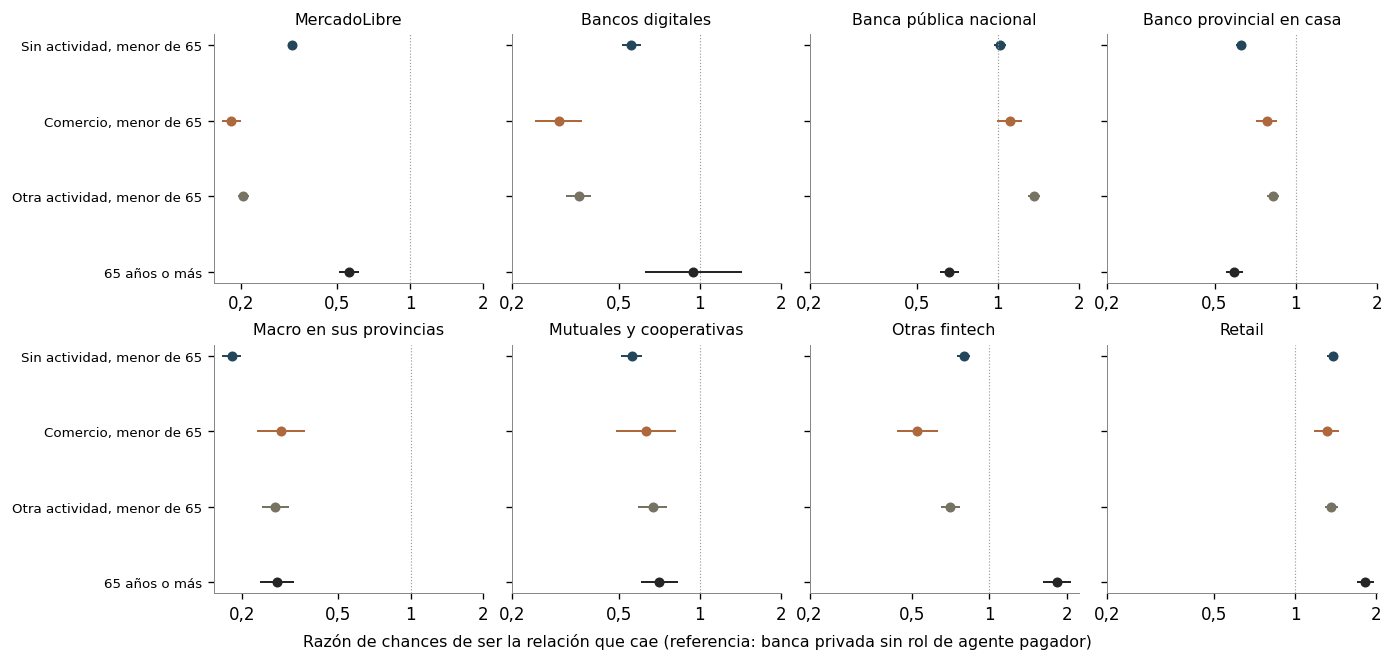

In [19]:
fig, axes = plt.subplots(2, 4, figsize=(11.5, 5.4), sharey=True, layout='constrained')
cols = [BLUE, OCHRE, OLIVE, INK]
for ax, k in zip(axes.flat, keys):
    for j, (lab, v) in enumerate(het.items()):
        r_ = v.loc[k]
        ax.plot([r_['lo'], r_['hi']], [j, j], color=cols[j], linewidth=1.2)
        ax.plot(r_['or'], j, 'o', color=cols[j], markersize=5)
    ax.axvline(1, color=GREY, linewidth=0.7, linestyle=':'); ax.set_xscale('log')
    ax.set_xticks([0.2, 0.5, 1, 2]); ax.set_xticklabels(['0,2', '0,5', '1', '2']); ax.minorticks_off()
    ax.set_title(lab_k[k], fontsize=9.5)
    ax.set_yticks(range(len(het))); ax.set_yticklabels(list(het.keys()), fontsize=8)
axes[0, 0].invert_yaxis()
fig.supxlabel('Razón de chances de ser la relación que cae (referencia: banca privada sin rol de agente pagador)', fontsize=9.5)
save(fig, '07_fuente_de_ingreso'); plt.show()

Las predicciones se cumplen, con una excepción que conviene registrar.

Entre los jubilados, la banca pública nacional pasa a estar protegida, mientras que para el resto está en torno a 1 o por encima: el haber llega a un banco pagador y ese banco se cobra. En cambio, MercadoLibre pierde buena parte de su ventaja entre los jubilados, y los bancos digitales la pierden casi entera. Entre quienes tienen actividad registrada ocurre lo contrario: MercadoLibre y los bancos digitales están más protegidos que en cualquier otro grupo. El banco provincial en casa y Macro en sus provincias están más protegidos entre quienes no tienen actividad registrada, que es donde están los asalariados públicos. Los jubilados también protegen al banco provincial en casa, lo que es compatible con que las cajas previsionales provinciales no transferidas paguen a través de ese banco. Y entre los jubilados, todo lo que no es su banco pagador cae antes: las otras fintech y el retail tienen cerca del doble de chances que la referencia.

La excepción son las mutuales. Esperaba que su protección se concentrara en los jubilados, por el código de descuento sobre haberes; no es así, es más fuerte entre asalariados sin actividad registrada. Es compatible con que las mutuales de la muestra operen sobre todo con descuento sobre sueldos públicos, pero no lo verifica.

Respecto de la advertencia de la sección 6: la lectura de acceso, pagarle al banco provincial para no perder la única alternativa, no predice que la protección dependa de si el deudor tiene actividad registrada. La lectura del débito sobre el sueldo sí. El patrón favorece a la segunda, sin descartar que las dos operen.

## 8. ¿Cambió el orden con el deterioro de 2025?

La tasa de primer evento subió de forma marcada en la segunda mitad de 2025. Si el orden fuera una respuesta al estrés, por ejemplo porque los deudores concentran pagos en quien puede ejecutarlos cuando el estrés aumenta, las diferencias deberían ampliarse en ese período.

In [20]:
periods = {'09/2024 a 05/2025': d.ym <= 2025 * 12 + 4,
           '06/2025 a 12/2025': d.ym.between(2025 * 12 + 5, 2025 * 12 + 11),
           '01/2026 a 06/2026': d.ym >= 2026 * 12}
per_or = pd.concat({lab: clogit(d[m], 'y', CB + SIZE + AGE)[0]['or'] for lab, m in periods.items()}, axis=1).loc[CB]
per_or.index = [lab_k.get(i, i[2:] if i.startswith('c_') else i) for i in per_or.index]
per_or.to_csv(po.OUT / '08_estabilidad.csv')
display(per_or)

,09/2024 a 05/2025,06/2025 a 12/2025,01/2026 a 06/2026
Banca pública nacional,0.973,0.951,1.207
Bancos digitales,0.436,0.467,0.462
Compañía financiera,0.740,0.658,0.784
Financiera digital,1.140,0.526,0.588
Tarjeta no bancaria,0.884,0.944,1.183
MercadoLibre,0.266,0.261,0.307
Otras fintech,0.929,0.679,0.902
Retail,1.458,1.312,1.612
Financiera de consumo,1.375,1.176,1.445
Mutuales y cooperativas,0.704,0.499,0.606


El orden es estable. MercadoLibre, bancos digitales, Macro en sus provincias y los bancos provinciales en casa mantienen sus razones de chances en los tres períodos, y retail y financieras de consumo siguen abajo. Hay deriva en 2026 en el medio de la tabla: la banca pública nacional, las tarjetas no bancarias y los otros PNFC pasan a caer algo más que la referencia. El movimiento más grande son las financieras digitales, que pasan de estar en torno a 1 antes de junio de 2025 a estar claramente protegidas después. Naranja Digital domina esa categoría y es la entidad que presta a través de la billetera Naranja X, así que el cambio es compatible con más ingresos pasando por esa billetera, aunque no lo prueba.

Que el orden no reaccione al estrés es informativo en sí mismo: apunta a una propiedad estructural del acreedor, su acceso al flujo, más que a una decisión estratégica que se ajusta con el ciclo.

## 9. Una medida independiente: la recategorización obligatoria

La normativa de clasificación de deudores obliga a una entidad a recategorizar a un deudor cuando otras entidades lo clasifican más de un nivel peor. El corte de deudores de julio de 2026 marca esas relaciones (`forced_reclass`). Antes de usarlo se verifica que signifique eso: en las relaciones marcadas, casi siempre hay otra entidad que clasifica peor al mismo deudor, típicamente un nivel peor.

Una relación recategorizada es, casi por definición, una relación donde la experiencia propia del acreedor era mejor que la de los demás. La proporción de la mora de cada acreedor que es recategorización obligatoria es entonces una medida de prioridad que no usa el panel, ni la muestra, ni el modelo: sale del corte transversal de toda la población.

In [21]:
D = (po.CENDEU / 'deudores.parquet').as_posix()
check = con.execute(f'''
  WITH fc AS (SELECT DISTINCT cuit FROM read_parquet('{D}') WHERE forced_reclass = 1
              AND substr(cuit, 1, 2) IN ('20', '23', '24', '27') AND loans_ars > 0),
  rel AS (SELECT d.ent, d.cuit, d.status, d.forced_reclass AS f FROM read_parquet('{D}') d SEMI JOIN fc USING (cuit) WHERE d.loans_ars > 0),
  o AS (SELECT a.status, max(b.status) FILTER (WHERE b.status <> 11) AS peor_otro
        FROM rel a LEFT JOIN rel b ON a.cuit = b.cuit AND a.ent <> b.ent WHERE a.f = 1 GROUP BY a.ent, a.cuit, a.status)
  SELECT status AS situacion, count(*) AS relaciones_recategorizadas,
         100 * avg((peor_otro > status)::INT) AS pct_otro_clasifica_peor,
         100 * avg((peor_otro = status + 1)::INT) AS pct_exactamente_un_nivel
  FROM o GROUP BY 1 ORDER BY 1''').fetchdf()
display(check)
forced = con.execute(f'''
  SELECT ent, count(*) FILTER (WHERE status BETWEEN 2 AND 4) AS mora_2a4,
         100 * avg((forced_reclass = 1)::INT) FILTER (WHERE status BETWEEN 2 AND 4) AS pct_recategorizada
  FROM read_parquet('{D}') WHERE substr(cuit, 1, 2) IN ('20', '23', '24', '27') AND loans_ars > 0
  GROUP BY 1''').fetchdf()
forced['categoria'] = forced.ent.map(cat.set_index('ent').cat)
f = forced[forced.mora_2a4 > 0]
fc_cat = (f.assign(w=f.pct_recategorizada * f.mora_2a4).groupby('categoria')[['w', 'mora_2a4']].sum()
          .assign(pct_recategorizada=lambda x: x.w / x.mora_2a4).drop(columns='w')
          .sort_values('pct_recategorizada', ascending=False))
fc_cat.to_csv(po.OUT / '09_recategorizacion_categorias.csv')
display(fc_cat)

,situacion,relaciones_recategorizadas,pct_otro_clasifica_peor,pct_exactamente_un_nivel
0,2,119058,98.861,22.275
1,3,235666,98.728,58.069
2,4,295355,89.170,89.170
3,5,2237,0.000,0.000


,mora_2a4,pct_recategorizada
categoria,,
MercadoLibre,913166,24.534
Mutual o cooperativa,84850,23.012
Banco digital,57819,16.173
Banco privado,1506697,14.345
Banco público,705895,11.070
Compañía financiera,23679,8.649
Tarjeta no bancaria,731027,7.049
Retail,322257,4.151
Garantía,8005,3.973


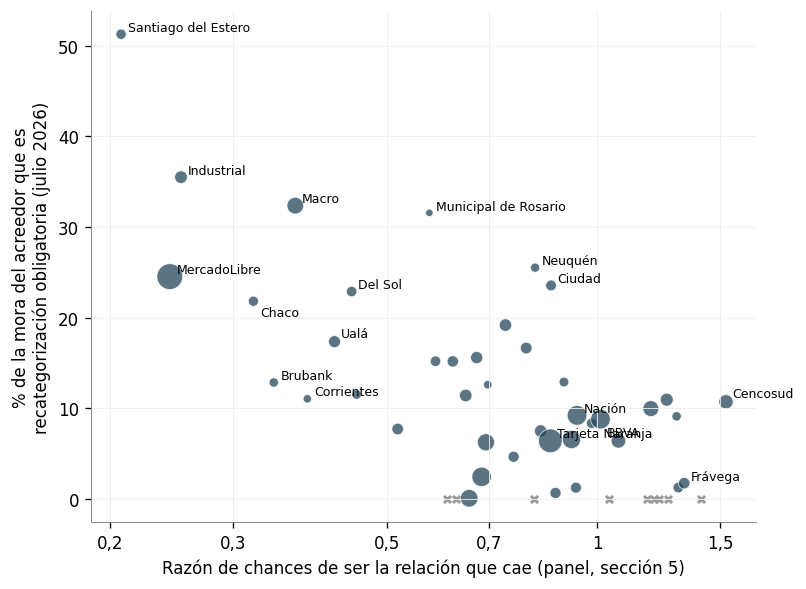

Correlación de rangos entre las dos medidas, entidades que aplican la regla: **-0,59** (n = 41). El signo negativo es el esperado: una razón de chances baja (acreedor protegido) va con una proporción alta de mora recategorizada. Las cruces grises son entidades con 0% exacto de recategorizaciones, que no parecen aplicar la regla.

,nombre,categoria,or,pct_recategorizada,mora_2a4
0,Santiago del Estero,Banco privado,0.208,51.281,23268
2,Industrial,Banco privado,0.253,35.512,52160
6,Macro,Banco privado,0.369,32.365,159396
12,Municipal de Rosario,Banco público,0.574,31.571,6487
28,Neuquén,Banco público,0.814,25.523,14399
1,MercadoLibre,MercadoLibre,0.244,24.534,913166
31,Ciudad,Banco público,0.858,23.562,27808
9,Del Sol,Banco privado,0.444,22.889,24422
3,Chaco,Banco público,0.321,21.817,21822
24,Columbia,Banco privado,0.738,19.183,49971


In [22]:
v = ent_tab.merge(forced[['ent', 'mora_2a4', 'pct_recategorizada']], on='ent', how='left')
v = v[v.mora_2a4 >= 5000].copy()
v['nombre'] = [short_name(e, names.get(e, e)) for e in v.ent]
v['aplica'] = v.pct_recategorizada > 0      # 0% exacto: la entidad no parece aplicar la regla
rank_corr = v.loc[v.aplica, 'or'].rank().corr(v.loc[v.aplica, 'pct_recategorizada'].rank())
v[['ent', 'entidad', 'categoria', 'or', 'mora_2a4', 'pct_recategorizada', 'aplica']].to_csv(po.OUT / '09_validacion_recategorizacion.csv', index=False)
fig, ax = plt.subplots(figsize=(6.6, 4.8), layout='constrained')
a = v[v.aplica]
ax.scatter(a['or'], a.pct_recategorizada, s=np.sqrt(a.mora_2a4) / 4, color=BLUE, alpha=0.75, edgecolor='white', linewidth=0.5)
ax.scatter(v.loc[~v.aplica, 'or'], np.zeros((~v.aplica).sum()), s=18, marker='x', color=GREY)
for _, row in a.iterrows():
    if row['or'] < 0.45 or row.pct_recategorizada > 20 or row.ent in (70147, 55030, 17, 7, 11, 70408):
        dy = {15: -9, 55294: -9, 70147: 3, 311: -9, 384: 3, 17: -10}.get(row.ent, 2)
        ax.annotate(row.nombre, (row['or'], row.pct_recategorizada), fontsize=7.5, xytext=(4, dy), textcoords='offset points')
ax.set_xscale('log'); ax.set_xticks([0.2, 0.3, 0.5, 0.7, 1, 1.5]); ax.set_xticklabels(['0,2', '0,3', '0,5', '0,7', '1', '1,5']); ax.minorticks_off()
ax.set(xlabel='Razón de chances de ser la relación que cae (panel, sección 5)',
       ylabel='% de la mora del acreedor que es\nrecategorización obligatoria (julio 2026)')
ax.grid(color='#eeeeee', linewidth=0.5)
save(fig, '09_validacion'); plt.show()
display(Markdown(f'Correlación de rangos entre las dos medidas, entidades que aplican la regla: **{es(rank_corr, 2)}** (n = {int(v.aplica.sum())}). El signo negativo es el esperado: una razón de chances baja (acreedor protegido) va con una proporción alta de mora recategorizada. Las cruces grises son entidades con 0% exacto de recategorizaciones, que no parecen aplicar la regla.'))
display(v.sort_values('pct_recategorizada', ascending=False)[['nombre', 'categoria', 'or', 'pct_recategorizada', 'mora_2a4']].head(12))

Las dos medidas cuentan la misma historia. Las entidades con más mora recategorizada, es decir, las que eran pagadas mientras el deudor caía en otras, son las que el panel ordena arriba: bancos que pagan sueldos provinciales, MercadoLibre, las mutuales y los bancos digitales. Las que casi no tienen son retail, financieras de consumo y las otras fintech. La coincidencia importa porque las dos medidas se construyen de forma distinta: una con flujos de la muestra y un modelo dentro de la persona, la otra con el stock de toda la población y una regla regulatoria.

No es una coincidencia perfecta. Neuquén, Ciudad y el Municipal de Rosario tienen mucha mora recategorizada y una protección moderada en el panel. Una lectura posible es que sus clientelas sean de empleados públicos que cobran allí pero a quienes el débito automático no se les aplica con la misma intensidad; otra, que la regla se aplique con criterios distintos entre entidades. No lo resuelvo acá.

La recategorización tiene además una consecuencia que vale anotar: traslada la mora de un acreedor a los demás en la información pública, y con ella las previsiones. Los acreedores que el deudor prioriza terminan previsionando préstamos que se les están pagando. Un cuarto de la mora reportada de MercadoLibre es de ese tipo.

## 10. Qué queda en pie y qué abre

**Lo que queda en pie.** Los hogares no caen en todas sus deudas a la vez: eligen, y la elección persiste. El orden por acreedor es marcado, estable en el tiempo y robusto a salidas, tamaño relativo, antigüedad, criterio de reporte y rezago. Lo ordena el acceso del acreedor al flujo de ingresos del deudor, y lo que sostiene esa lectura no es solo el ranking sino tres cortes que el mecanismo predice y las lecturas alternativas no: Macro en sus provincias contra fuera de ellas, el gradiente por tamaño de provincia de los bancos provinciales, y el cambio de la prioridad con la fuente de ingreso del deudor. Una medida regulatoria independiente reproduce el orden.

**Lo que no queda resuelto.**

- Débito sobre el flujo contra exclusión futura. MercadoLibre puede cobrarse de la billetera, pero también puede cortar el acceso a la plataforma. Los dos canales predicen protección. El corte por actividad registrada favorece al débito, no lo aísla.
- Acceso local contra sueldo, para los bancos provinciales. Separarlo requiere puntos de acceso por localidad y el código postal del padrón.
- Producto. El panel no identifica si una relación bancaria es tarjeta o préstamo, y el campo de asistencia no utilizada del corte de deudores está vacío, así que no sirve para separarlo. Las garantías preferidas sí están, pero solo en el corte de julio de 2026.
- El peso del empleo público por provincia no está en el proyecto; con él, el gradiente de la sección 6 pasa de sugerencia a test.

**Lo que abre.**

1. *Precio de la prioridad.* Si retail y financieras de consumo son los últimos en cobrar, deberían cobrar tasas más altas por el mismo deudor. Las tasas de PNFC pedidas al BCRA permitirían ver si la prioridad se paga.
2. *Dilución.* Un acreedor que cobra primero impone una externalidad sobre los demás. Cuando una persona toma crédito de MercadoLibre, ¿sube el riesgo de sus deudas con retail? Es el problema de no exclusividad de Bizer y DeMarzo con senioridad tecnológica en lugar de contractual.
3. *Conexión con la expansión fintech.* MercadoLibre creció 48% real mientras el crédito regular de la banca privada a hogares caía. Un prestamista que es senior de hecho puede expandirse hacia una población en deterioro con menos pérdida esperada. Es una explicación de la sustitución que no depende de la liquidez bancaria.
4. *La regla de recategorización como canal.* Es un mecanismo regulatorio de contagio de la mora reportada entre acreedores, con costo en previsiones para los acreedores que el deudor prioriza.

**Literatura contra la que ubicarlo.** Andersson, Chomsisengphet, Glennon y Li (2013, *JMCB*) documentan el orden de impago entre productos en Estados Unidos; aquí el orden es entre acreedores dentro de la misma persona, que es lo que permite absorber la capacidad de pago. Coelho, de Mello y Funchal (2012, *REStat*) muestran que el descuento sobre nómina en Brasil abarata el crédito; lo que aparece aquí es la otra cara, la prioridad que ese descuento compra frente a los demás acreedores. La literatura reciente sobre fintech de pagos y cobro sobre flujos es la vecindad más cercana; este diseño agrega la comparación contra todos los demás acreedores del mismo deudor.

In [23]:
con.close()
po.cleanup(tmp)
print('Intermedios borrados:', not tmp.exists())

Intermedios borrados: True
